We will solve the Fashion MNIST dataset using a simple CNN network

In [1]:
import os
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

In [2]:
class FashionCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=5, padding=2),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(32, 64, kernel_size=5, padding=2),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [3]:
def run_epoch(model, loader, loss_fn, opt=None):
    is_train = opt is not None
    model.train(is_train)
    total_loss = 0.0
    correct = 0
    total = 0
    for images, labels in loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)
        if is_train:
            opt.zero_grad()
        with torch.set_grad_enabled(is_train):
            preds = model(images)
            loss = loss_fn(preds, labels)
            if is_train:
                loss.backward()
                opt.step()
        total_loss += loss.item()
        correct += (preds.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return total_loss / len(loader), 100 * correct / total

In [8]:
DEVICE = "cuda"
EPOCHS = 30
BATCH_SIZE = 128
PATIENCE = 5
MODEL_PATH = "weights/fashion_cnn.pth"

In [5]:
transform = transforms.Compose([
    transforms.ToTensor(),
])

full_train = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=transform,
)
test_data = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=transform,
)

train_data, val_data = random_split(full_train, [50000, 10000])
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE)

100%|██████████| 26.4M/26.4M [00:02<00:00, 11.0MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 172kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.17MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 19.1MB/s]


In [9]:
model = FashionCNN().to(DEVICE)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss()

print("device:", DEVICE)
print("training Fashion MNIST with vanilla CNN")

os.makedirs("weights", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

train_losses = []
val_losses = []
best_val_loss = float("inf")
epochs_no_improve = 0
stopped_epoch = EPOCHS

device: cuda
training Fashion MNIST with vanilla CNN


In [10]:
for epoch in range(EPOCHS):
    train_loss, train_acc = run_epoch(model, train_loader, loss_fn, opt)
    val_loss, val_acc = run_epoch(model, val_loader, loss_fn)
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    print(
        f"epoch {epoch + 1}/{EPOCHS} "
        f"train_loss={train_loss:.4f} train_acc={train_acc:.2f}% "
        f"val_loss={val_loss:.4f} val_acc={val_acc:.2f}%"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_no_improve = 0
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= PATIENCE:
            stopped_epoch = epoch + 1
            print(f"early stopping at epoch {stopped_epoch}")
            break


epoch 1/30 train_loss=0.5327 train_acc=80.71% val_loss=0.3488 val_acc=87.17%
epoch 2/30 train_loss=0.3289 train_acc=88.32% val_loss=0.3095 val_acc=88.63%
epoch 3/30 train_loss=0.2742 train_acc=90.01% val_loss=0.2737 val_acc=89.92%
epoch 4/30 train_loss=0.2416 train_acc=91.26% val_loss=0.2481 val_acc=91.14%
epoch 5/30 train_loss=0.2189 train_acc=91.99% val_loss=0.2521 val_acc=90.33%
epoch 6/30 train_loss=0.1983 train_acc=92.64% val_loss=0.2505 val_acc=90.92%
epoch 7/30 train_loss=0.1802 train_acc=93.30% val_loss=0.2336 val_acc=91.38%
epoch 8/30 train_loss=0.1611 train_acc=94.05% val_loss=0.2284 val_acc=92.09%
epoch 9/30 train_loss=0.1448 train_acc=94.65% val_loss=0.2158 val_acc=92.51%
epoch 10/30 train_loss=0.1304 train_acc=95.19% val_loss=0.2287 val_acc=92.05%
epoch 11/30 train_loss=0.1193 train_acc=95.48% val_loss=0.2345 val_acc=92.15%
epoch 12/30 train_loss=0.0997 train_acc=96.37% val_loss=0.2366 val_acc=92.74%
epoch 13/30 train_loss=0.0928 train_acc=96.59% val_loss=0.2474 val_acc=92

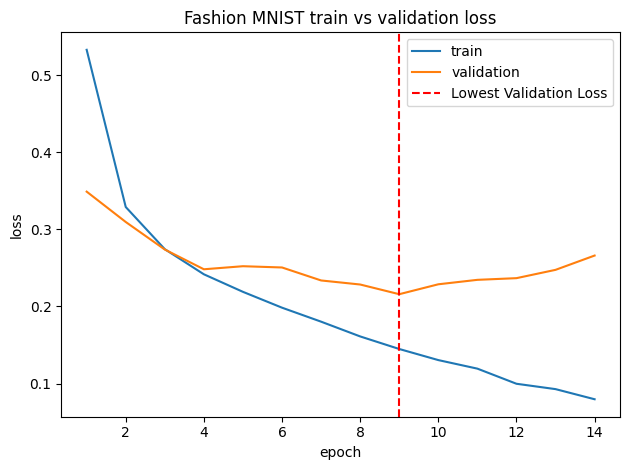

In [12]:
plt.figure()
epochs_ran = range(1, len(train_losses) + 1)
plt.plot(epochs_ran, train_losses, label="train")
plt.plot(epochs_ran, val_losses, label="validation")

plt.axvline(x=epochs_ran[val_losses.index(best_val_loss)], color='r', linestyle='--',
            label='Lowest Validation Loss')

plt.xlabel("epoch")
plt.ylabel("loss")
plt.title("Fashion MNIST train vs validation loss")
plt.legend()
plt.tight_layout()
plt.show()

In [13]:
print(f"retraining on train+val for {stopped_epoch - PATIENCE} epochs")
full_loader = DataLoader(full_train, batch_size=BATCH_SIZE, shuffle=True)
model = FashionCNN().to(DEVICE)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)

for epoch in range(stopped_epoch - PATIENCE):
    train_loss, train_acc = run_epoch(model, full_loader, loss_fn, opt)
    print(
        f"retrain epoch {epoch + 1}/{stopped_epoch - PATIENCE} "
        f"loss={train_loss:.4f} acc={train_acc:.2f}%"
    )

torch.save(model.state_dict(), MODEL_PATH)
print(f"saved model to {MODEL_PATH}")

retraining on train+val for 9 epochs
retrain epoch 1/9 loss=0.5030 acc=81.63%
retrain epoch 2/9 loss=0.3181 acc=88.41%
retrain epoch 3/9 loss=0.2700 acc=90.17%
retrain epoch 4/9 loss=0.2381 acc=91.31%
retrain epoch 5/9 loss=0.2161 acc=92.04%
retrain epoch 6/9 loss=0.1948 acc=92.86%
retrain epoch 7/9 loss=0.1775 acc=93.49%
retrain epoch 8/9 loss=0.1607 acc=94.13%
retrain epoch 9/9 loss=0.1465 acc=94.60%
saved model to weights/fashion_cnn.pth


In [14]:
test_loss, test_acc = run_epoch(model, test_loader, loss_fn)
print(f"test loss={test_loss:.4f}  test accuracy={test_acc:.2f}%")

test loss=0.2442  test accuracy=91.38%
